# [County] County Prosecution Analysis

**Source:** [County] prosecution extract
**Study period:** 2017 to 2024 (filing year)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge (felony over misdemeanor, then statutory class).
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

## Setup

In [1]:
import sys
!{sys.executable} -m pip install -U "openpyxl>=3.1"


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)

set_style()

COUNTY = "hampden"        # e.g. "worcester"
YEARS = range(2017, 202)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
Fill in the paths and map your extract's column names onto the shared names.
If your county has a single file, point both `FILED_PATH` and `DISPOSED_PATH` at it.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

FILED_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Data_-_Filed_17-25_2.csv"   # all filed charges (includes open cases)
DISPOSED_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Data_-_Dispo_17-25.csv"  # disposed charges

def read_any(path):
    """Read once, then reuse a fast pickle copy saved next to the file."""
    cache = Path(path).with_suffix(".pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    if path.endswith(".parquet"):
        df = pd.read_parquet(path)
    elif path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, dtype=str)
    else:
        # Excel can save "CSV" with ; instead of , -> detect it from the header line
        for enc in ("utf-8-sig", "cp1252"):
            try:
                with open(path, encoding=enc) as f:
                    header = f.readline()
                sep = ";" if header.count(";") > header.count(",") else ","
                df = pd.read_csv(path, sep=sep, low_memory=False, dtype=str, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
    df.columns = df.columns.str.strip()      # Hampden headers have trailing spaces
    df.to_pickle(cache)
    return df

# Shared name : Hampden column name. None = not in the extract.
COLS = {
    "docket_number":    "Case ID Number",
    "defendant_id":     "Defendant ID Number",
    "charge_count":     "Count",               # Count = 1 is the lead charge
    "filing_date":      "Filing Date",
    "disposition_date": "Dispo Date",
    "disposition":      "Dispo Code",          # e.g. NOP, CWOF; same column in both files
    "charge_level":     "Case Type",           # e.g. FE; check it's felony/misdemeanor (see checks below)
    "offense_category": "Crime Type",          # e.g. CA, LAR
    "court":            "Court",               # codes, e.g. HS, SD
    "race":             "Race",
    "sex":              "Gender",
    "sentence_type":    "Sentence Type",
}

def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    out = raw.rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = np.nan
    out["case_key"] = out["docket_number"].astype(str) + "_" + out["defendant_id"].astype(str)
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out["disposition_date"] = pd.to_datetime(out["disposition_date"], errors="coerce")
    out["filing_year"] = out["filing_date"].dt.year
    return out

raw_filed = read_any(FILED_PATH)
raw_disposed = read_any(DISPOSED_PATH)
filed = standardize(raw_filed)
disposed = standardize(raw_disposed)

# The Dispo file cuts off Filing Date (e.g. "08/06/201"), so take it from the Filed file per case.
case_filing = filed.groupby("docket_number")["filing_date"].min()
bad = disposed["filing_date"].isna() | (disposed["filing_date"].dt.year < 2000)
disposed.loc[bad, "filing_date"] = disposed.loc[bad, "docket_number"].map(case_filing)
disposed["filing_year"] = disposed["filing_date"].dt.year

missing_cols = [k for k, v in COLS.items() if v is None or v not in raw_filed.columns]
print("Not found in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")
print(f"Disposed filing dates still missing after repair: {disposed['filing_date'].isna().mean():.1%}")

print("\nFiling years (filed):")
print(filed["filing_year"].value_counts().sort_index().tail(12))
print("\nDisposition years (disposed):")
print(disposed["disposition_date"].dt.year.value_counts().sort_index().tail(12))
print("\nCase Type (felony/misdemeanor?):")
print(filed["charge_level"].value_counts(dropna=False).head(10))
print("\nDisposition codes (for OUTCOME_ALIASES):")
print(disposed["disposition"].value_counts(dropna=False).head(30))
print("\nCourt codes:")
print(filed["court"].value_counts(dropna=False))

/var/folders/5k/8xhyhd0j7jx98f4ydy5f5tmm0000gn/T/ipykernel_58978/92088598.py:56: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  out["disposition_date"] = pd.to_datetime(out["disposition_date"], errors="coerce")
/var/folders/5k/8xhyhd0j7jx98f4ydy5f5tmm0000gn/T/ipykernel_58978/92088598.py:55: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")


Not found in extract: []
Filed: 372,589 charges, 149,693 cases
Disposed: 388,259 charges, 138,239 cases
Disposed filing dates still missing after repair: 0.0%

Filing years (filed):
filing_year
2017.0    18528
2018.0    20195
2019.0    18240
2020.0    14568
2021.0    15794
2022.0    14579
2023.0    17253
2024.0    16654
2025.0    16924
Name: count, dtype: int64

Disposition years (disposed):
disposition_date
2020.0     9647
2021.0    15412
2022.0    16199
2023.0    16179
2024.0    16221
2025.0    14799
2026.0        9
2028.0       15
2035.0        2
2081.0       11
2108.0        3
2204.0        4
Name: count, dtype: int64

Case Type (felony/misdemeanor?):
charge_level
MI    219377
FE    152782
IN       200
OR       190
ID        37
SD         3
Name: count, dtype: int64

Disposition codes (for OUTCOME_ALIASES):
disposition
NOP         116776
2003        101050
NOT-RESP     35618
CWOF         20806
GLT-CMTD     15905
2000         13392
GLT-PROB     12287
NaN          10657
276          

## Map Dispositions and Exclusions
Run the value counts, then map every disposition onto the shared buckets:
**Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**, plus **Pending** for open charges.
Nolle prosequi counts as Dismissal. Unmapped values fall into Other, so check that the Other share is small.

In [4]:
disposed["disposition"].value_counts(dropna=False).head(40)

disposition
NOP         116776
2003        101050
NOT-RESP     35618
CWOF         20806
GLT-CMTD     15905
2000         13392
GLT-PROB     12287
NaN          10657
276           9697
2004          9579
RESF          7943
GLT-FILE      7281
GLT-CON       5667
RES           4535
TS            4002
GLTSS         3969
2001          2392
GLT-FINE      2325
DCD           1334
GCS            619
SPS            460
NTGLT          392
GLESS          356
DIRV           189
CLT            179
GCC            168
GLT-LIFE       167
VA              87
DYSC            50
2006            47
86              32
DYSS            31
NGI             28
CSC             28
CC              24
92              21
NPFARAK         20
COMS            20
54              16
55              14
Name: count, dtype: int64

In [5]:
COUNTY_OUTCOMES = {
    # "raw disposition value": "Shared bucket",
    # "dismissed": "Dismissal",
    # "nolle prosequi": "Dismissal",
    # "guilty": "Plea",
    # "jury trial guilty": "Trial Conviction",
    # "CWOF": "CWOF",
    # "pretrial probation": "Diversion",
    # "jury trial not guilty": "Acquittal",
    # "no disposition": "Pending",
}

# Non-criminal outcomes (e.g. civil infractions) and offense categories the client excluded
EXCLUDE_DISPOSITIONS = []   # raw disposition values for civil / non-criminal matters
EXCLUDE_OFFENSES = []       # e.g. ["Motor Vehicle"]

disposed["outcome"] = disposed["disposition"].replace(COUNTY_OUTCOMES).map(normalize_outcome)
disposed = disposed[~disposed["disposition"].isin(EXCLUDE_DISPOSITIONS)]
disposed = disposed[~disposed["offense_category"].isin(EXCLUDE_OFFENSES)]
filed = filed[~filed["offense_category"].isin(EXCLUDE_OFFENSES)]

print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

outcome
Other      356796
CWOF        20806
Unknown     10657
Name: count, dtype: int64
Share in Other: 91.9%


## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [6]:
print(filed["charge_level"].value_counts(dropna=False))

charge_level
MI    219377
FE    152782
IN       200
OR       190
ID        37
SD         3
Name: count, dtype: int64


In [7]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

coverage = pd.DataFrame({
    "pct_missing": [disposed[f].isna().mean() * 100 for f in COVERAGE_FIELDS],
    "years_available": [years_available(disposed, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'disposition_date', 'sentence_type'}


,pct_missing,years_available,status
docket_number,0.0,2000-2026,ok
defendant_id,0.0,2000-2026,ok
filing_date,0.0,2000-2026,ok
disposition_date,62.8,2000-2026,insufficient data
disposition,2.7,2000-2026,ok
charge_level,0.0,2000-2026,ok
offense_category,0.0,2000-2026,ok
court,0.2,2000-2026,ok
race,10.1,2000-2026,ok
sex,2.8,2000-2026,ok


**Notes:** [Describe any coverage gaps, e.g. a field only recorded after a certain year.]

## Build Case Table
One row per case (docket × defendant), restricted to filing years 2017 to 2024.
- **Most serious charge:** felony over misdemeanor, then lowest charge number as a tiebreak. Replace the tiebreak with statutory class if your extract has it.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [9]:
LEVEL_RANK = {"FE": 1, "MI": 2}  # Hampden Case Type: FE = felony, MI = misdemeanor; IN, OR, ID, SD rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].copy()
    d = d.drop_duplicates()                                   # Hampden repeats identical charge rows
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    # Lead charge = most serious level, then lowest Count. Keep that whole row (not .first(), which mixes rows).
    lead = (d.sort_values(["case_key", "level_rank", "charge_count_num"])
              .drop_duplicates("case_key")
              .set_index("case_key"))
    g = d.groupby("case_key")
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": g["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": g["charge_count_num"].nunique(),         # distinct charges, not duplicate rows
    })
    if with_outcome:
        out["outcome"] = g["outcome"].agg(case_outcome)
        out["disposition_date"] = g["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()
YEARS = list(range(2017, 2025))   
print(f"Filed cases {min(YEARS)}-{max(YEARS)}: {len(filed_cases):,}")
print(f"Disposed cases {min(YEARS)}-{max(YEARS)}: {len(cases):,} ({n_pending:,} pending excluded)")
print(f"Duplicate rows dropped: filed {filed.duplicated().sum():,}, disposed {disposed.duplicated().sum():,}")

Filed cases 2017-2024: 53,916
Disposed cases 2017-2024: 118,960 (0 pending excluded)
Duplicate rows dropped: filed 20,707, disposed 63,963


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

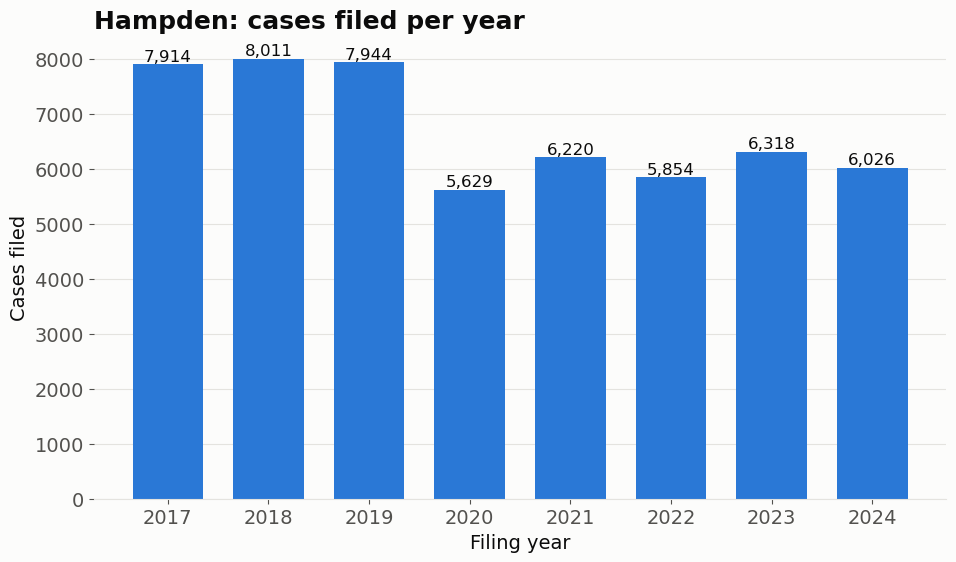

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017.0,7914,NaN,0.0
2018.0,8011,1.2,1.2
2019.0,7944,-0.8,0.4
2020.0,5629,-29.1,-28.9
2021.0,6220,10.5,-21.4
2022.0,5854,-5.9,-26.0
2023.0,6318,7.9,-20.2
2024.0,6026,-4.6,-23.9


In [10]:
vol = filed_cases.groupby("filing_year").size().rename("cases").to_frame()
vol["pct_change_yoy"] = (vol["cases"].pct_change() * 100).round(1)
vol["pct_change_vs_2017"] = ((vol["cases"] / vol["cases"].iloc[0] - 1) * 100).round(1)

fig, ax = plt.subplots()
ax.bar(vol.index, vol["cases"], color=OUTCOME_COLORS["Trial Conviction"], width=0.7)
for x, n in zip(vol.index, vol["cases"]):
    ax.text(x, n, f"{n:,}", ha="center", va="bottom", fontsize=12)
ax.set_xticks(list(vol.index))
ax.set_ylabel("Cases filed")
ax.set_xlabel("Filing year")
ax.set_title(f"{COUNTY.title()}: cases filed per year")
save_fig(fig, f"{FIG_DIR}/q1_volume.png")
plt.show()
vol

**How this was calculated**
- **Unit:** cases (docket × defendant)
- **Source:** filed extract, so open cases are counted
- **Date field:** filing date (earliest charge in the case)
- **Filters:** filing years 2017 to 2024; [exclusions]

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

In [11]:
POPULATION = {  # annual county population estimates (Census PEP or ACS)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}

pop = pd.Series(POPULATION, dtype="float")
if pop.isna().any():
    print("Fill in POPULATION for:", list(pop.index[pop.isna()]))
else:
    per_cap = (vol["cases"] / pop * 10_000).round(1).rename("cases_per_10k").to_frame()
    fig, ax = plt.subplots()
    ax.plot(per_cap.index, per_cap["cases_per_10k"], marker="o", markersize=8,
            linewidth=2, color=OUTCOME_COLORS["Trial Conviction"])
    for x, v in zip(per_cap.index, per_cap["cases_per_10k"]):
        ax.annotate(f"{v:.0f}", (x, v), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=12)
    ax.set_xticks(list(per_cap.index))
    ax.set_ylabel("Cases per 10,000 residents")
    ax.set_xlabel("Filing year")
    ax.set_title(f"{COUNTY.title()}: cases filed per 10,000 residents")
    save_fig(fig, f"{FIG_DIR}/q2_per_capita.png")
    plt.show()
    display(per_cap)

Fill in POPULATION for: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


**How this was calculated**
- **Numerator:** cases filed per year (from Q1)
- **Denominator:** [population source and vintage]

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

In [12]:
import viz_style

# Split Hampden convictions into trial vs plea using Dispo Description (TRJR = jury trial, TRBN = bench trial).
desc_col = "Dispo Desription" if "Dispo Desription" in disposed.columns else "Dispo Description"
is_conviction = disposed["disposition"].astype(str).str.startswith(("GLT", "GLESS"))
is_trial = disposed[desc_col].isin(["TRJR", "TRBN"])
disposed.loc[is_conviction & is_trial, "disposition"] = "GLT-TRIAL"
print(f"Trial convictions: {(is_conviction & is_trial).sum():,} of {is_conviction.sum():,} conviction charges")

# Hampden disposition codes -> shared buckets (viz_style.OUTCOME_COLORS)
viz_style.OUTCOME_ALIASES.update({
    "CWOF":      "CWOF",
    "NTGLT":     "Acquittal",
    "NOP":       "Dismissal",          # nolle prosequi -> Dismissal (team rule); confirm NOP = nolle prosequi
    "GLT-TRIAL": "Trial Conviction",   # guilty + Dispo Description TRJR/TRBN
    "GLT-CMTD":  "Plea",               # other guilty codes: plea (PLAG/PLUG/PLUA/AGR/UNA) or method not recorded
    "GLT-PROB":  "Plea",
    "GLT-FILE":  "Plea",
    "GLT-FINE":  "Plea",
    "GLT-CON":   "Plea",
    "GLTSS":     "Plea",
    "GLESS":     "Plea",
    "NOT-RESP":  "Other",              # civil infractions, not criminal outcomes
    "RES":       "Other",
    "RESF":      "Other",
    "2000":      "Plea",               # plea descriptions (PLAG/PLUA)
    "2004":      "CWOF",               # sentence type CWOF / 24D (OUI program)
    "276":       "Diversion",          # c.276 §87 pretrial probation
    "TS":        "Plea",               # plea descriptions; sentence = time served
    "GCS":       "Plea",
    "DCD":       "Plea",
    "SPS":       "Plea",               # provisional
    "2003":      "Dismissal",          # PROVISIONAL: likely dismissed upon payment of court costs (COUC); confirm with codebook
    # 2001 (trial, verdict unclear) left as Other
})

disposed["outcome"] = disposed["disposition"].map(viz_style.normalize_outcome)
print(disposed["outcome"].value_counts())

Trial convictions: 879 of 47,957 conviction charges
outcome
Dismissal           217826
Plea                 66738
Other                51685
CWOF                 30385
Unknown              10657
Diversion             9697
Trial Conviction       879
Acquittal              392
Name: count, dtype: int64


,cases,pct
outcome,,
Dismissal,70499,59.3
Plea,22181,18.6
CWOF,16299,13.7
Other,5470,4.6
Diversion,3193,2.7
Unknown,1036,0.9
Trial Conviction,174,0.1
Acquittal,108,0.1


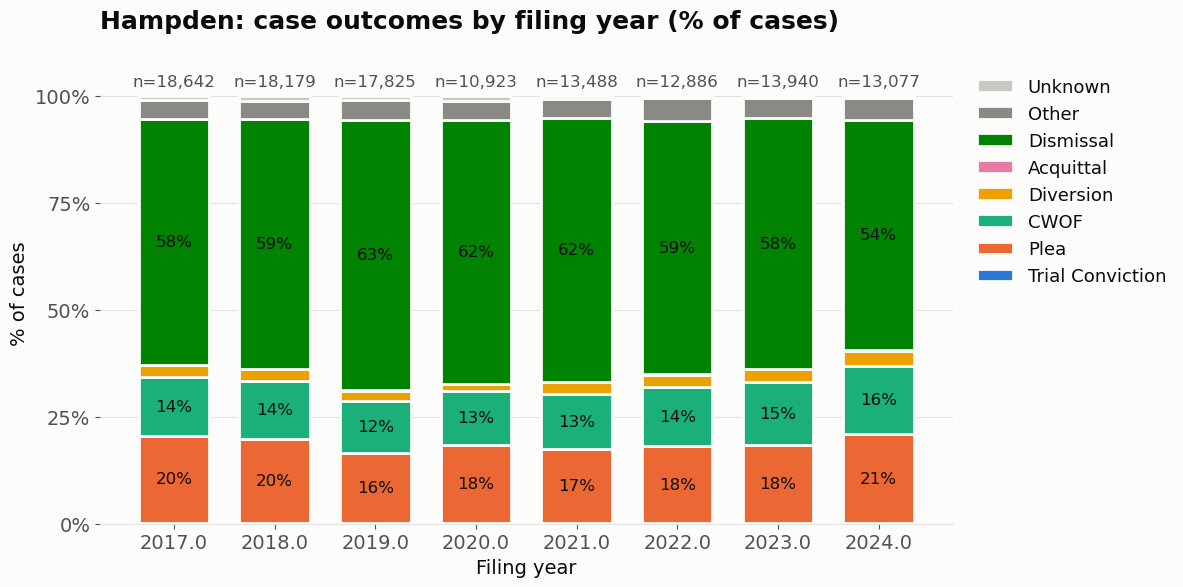

In [19]:
import viz_style

# Rebuild charge outcomes with the Hampden mapping, then rebuild cases, so this chart is always current.
disposed["outcome"] = disposed["disposition"].map(viz_style.normalize_outcome)
all_disposed_cases = build_cases(disposed, with_outcome=True)
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

overall = cases["outcome"].value_counts().rename("cases").to_frame()
overall["pct"] = (overall["cases"] / overall["cases"].sum() * 100).round(1)
display(overall)

counts = cases.groupby("filing_year")["outcome"].value_counts().unstack(fill_value=0)
ax = stacked_pct_bar(counts, unit="cases",
                     title=f"{COUNTY.title()}: case outcomes by filing year (% of cases)",
                     xlabel="Filing year")
save_fig(ax.figure, f"{FIG_DIR}/q3_outcomes_by_year.png")
plt.show()

In [13]:
for code in ["2003", "2000", "2004", "2001", "276", "TS", "DCD", "GCS", "SPS"]:
    sub = disposed[disposed["disposition"] == code]
    print(f"\n=== {code} ({len(sub):,} charges)")
    print(sub[desc_col].value_counts(dropna=False).head(4).to_string())
    print(sub["sentence_type"].value_counts(dropna=False).head(4).to_string())
    print(sub["Charge Description"].value_counts().head(3).to_string())


=== 2003 (101,050 charges)
Dispo Desription
NaN     37193
INDI    16252
COUC    13801
DCT      4386
sentence_type
NaN    76748
CC     14083
FI      3166
COM     2061
Charge Description
LICENSE SUSPENDED, OP MV WITH c90 Â§23    11204
UNLICENSED OPERATION OF MV c90 Â§10        9988
UNINSURED MOTOR VEHICLE c90 Â§34J          8330

=== 2000 (13,392 charges)
Dispo Desription
PLAG    6082
NaN     2378
PLUA    2283
OT      1127
sentence_type
NaN     4794
COM     4172
PROB     862
GF       830
Charge Description
DRUG, DISTRIBUTE CLASS A c94C Â§32(a)                         333
FIREARM VIOL WITH 1 PRIOR VIOLENT/DRUG CRIME c269 Â§10G(a)    332
A&B c265 Â§13A                                                332

=== 2004 (9,579 charges)
Dispo Desription
AGR    4887
NaN    2062
UNA    1291
OT      614
sentence_type
CWOF    4870
NaN     2834
24D     1501
PROB     107
Charge Description
OUI/LIQUOR SECOND OFFENSE                              781
NEGLIGENT OPERATION OF MOTOR VEHICLE c90 Â§24(2)(a)    7

In [20]:
print("Charge-level:", disposed["outcome"].value_counts().head(4).to_dict())
print("Case-level:  ", cases["outcome"].value_counts().head(4).to_dict())

Charge-level: {'Dismissal': 217826, 'Plea': 66738, 'Other': 51685, 'CWOF': 30385}
Case-level:   {'Dismissal': 70499, 'Plea': 22181, 'CWOF': 16299, 'Other': 5470}


,cases,pct
outcome,,
Dismissal,70499,59.3
Plea,22181,18.6
CWOF,16299,13.7
Other,5470,4.6
Diversion,3193,2.7
Unknown,1036,0.9
Trial Conviction,174,0.1
Acquittal,108,0.1


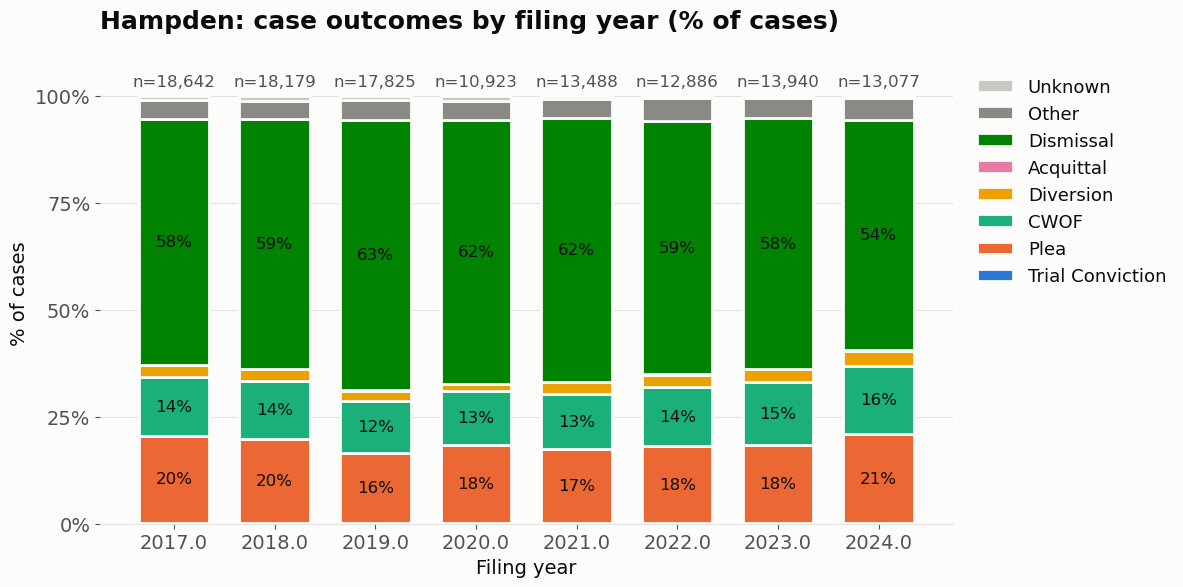

In [22]:
import viz_style

# Rebuild charge outcomes with the Hampden mapping, then rebuild cases, so this chart is always current.
disposed["outcome"] = disposed["disposition"].map(viz_style.normalize_outcome)
all_disposed_cases = build_cases(disposed, with_outcome=True)
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

overall = cases["outcome"].value_counts().rename("cases").to_frame()
overall["pct"] = (overall["cases"] / overall["cases"].sum() * 100).round(1)
display(overall)

counts = cases.groupby("filing_year")["outcome"].value_counts().unstack(fill_value=0)
ax = stacked_pct_bar(counts, unit="cases",
                     title=f"{COUNTY.title()}: case outcomes by filing year (% of cases)",
                     xlabel="Filing year")
save_fig(ax.figure, f"{FIG_DIR}/q3_outcomes_by_year.png")
plt.show()

**How this was calculated**
- **Unit:** disposed criminal cases (docket × defendant), pending cases excluded
- **Outcome rule:** most severe outcome across the case's charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown)
- **Date field:** filing year (Filing Date; for disposed charges with a truncated filing date, taken from the Filed extract)
- **Mapping (Hampden `Dispo Code`):**
  - **Dismissal:** NOP (nolle prosequi, per team rule), 2003 (*provisional: likely dismissed upon payment of court costs; Dispo Description COUC/INDI/DCT*)
  - **Plea:** GLT-CMTD, GLT-PROB, GLT-FILE, GLT-FINE, GLT-CON, GLTSS, GLESS (guilty, method plea or not recorded), 2000 (plea descriptions PLAG/PLUA), TS, GCS, DCD, SPS (*provisional*)
  - **Trial Conviction:** guilty codes whose Dispo Description is TRJR (jury trial) or TRBN (bench trial)
  - **CWOF:** CWOF, 2004 (sentence type CWOF / 24D OUI program)
  - **Diversion:** 276 (pretrial probation, c.276 §87)
  - **Acquittal:** NTGLT
  - **Other:** NOT-RESP, RES, RESF (civil infractions), 2001 (trial, verdict unclear), any unmapped code
  - **Unknown:** blank disposition code

**Note:** Cases filed in 2023 to 2024 that were still open at extraction are missing from the disposed extract, so recent years lean toward fast-resolving cases.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

In [23]:
print("INSUFFICIENT =", INSUFFICIENT)
conv_check = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])]
print(f"Sentence type filled for {conv_check['sentence_type'].notna().mean():.0%} of conviction charges")
print(conv_check["sentence_type"].value_counts(dropna=False).head(15))

INSUFFICIENT = {'disposition_date', 'sentence_type'}
Sentence type filled for 66% of conviction charges
sentence_type
NaN     23011
COM     19801
PROB     8061
SS       3635
TS       2986
CON      2983
GF       2781
FI       1889
S         983
CWOF      549
OA        541
24D       244
CC         83
276        20
DCT        19
Name: count, dtype: int64


In [24]:
HAMPDEN_SENTENCE = {
    "COM":  "Incarceration",   # committed
    "TS":   "Incarceration",   # time served
    "CON":  "Incarceration",   # provisional: likely concurrent commitment
    "PROB": "Probation",
    "SS":   "Probation",       # suspended sentence
    "S":    "Probation",       # provisional: likely suspended
    "24D":  "Probation",       # OUI program
    "CWOF": "Probation",       # CWOF terms are supervised
    "276":  "Probation",       # pretrial probation
    "FI":   "Fines/Other",     # fine
    "CC":   "Fines/Other",     # court costs
    "GF":   "Fines/Other",     # guilty-filed
    "OA":   "Fines/Other",     # provisional: meaning unknown
    "DCT":  "Fines/Other",     # provisional: meaning unknown
}

Missing sentence type: 32.8% of convicted cases


,cases,pct
sentence,,
Incarceration,7065,31.6
Probation,5303,23.7
Fines/Other,2661,11.9
Unknown,7326,32.8


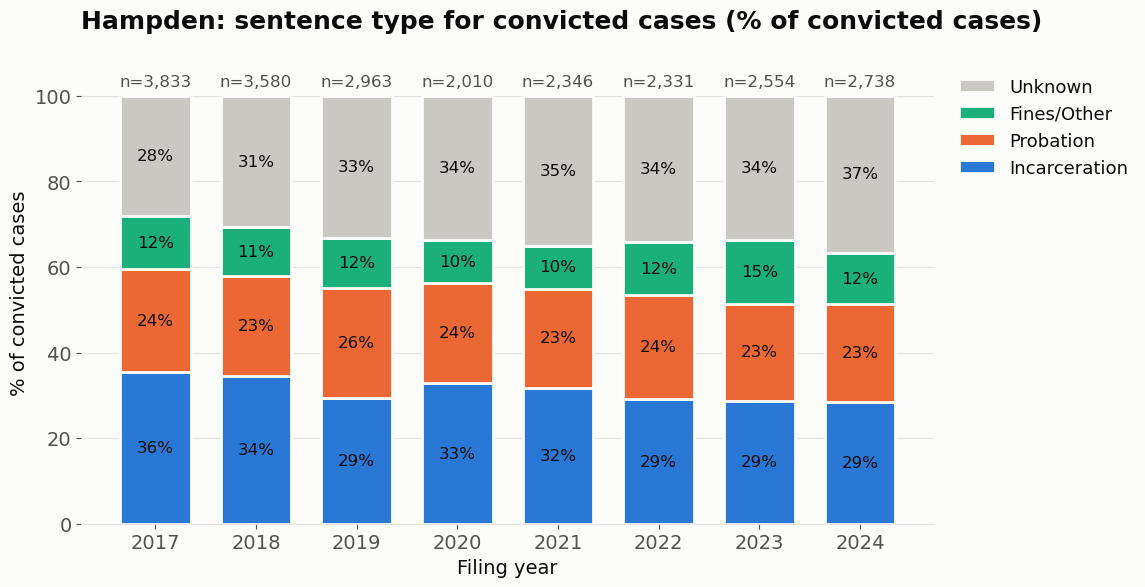

In [26]:
import viz_style

SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

# Hampden Sentence Type codes -> sentence buckets
HAMPDEN_SENTENCE = {
    "COM":  "Incarceration",   # committed
    "TS":   "Incarceration",   # time served
    "CON":  "Incarceration",   # provisional: likely concurrent commitment
    "PROB": "Probation",
    "SS":   "Probation",       # suspended sentence
    "S":    "Probation",       # provisional: likely suspended
    "24D":  "Probation",       # OUI program
    "CWOF": "Probation",       # CWOF terms are supervised
    "276":  "Probation",       # pretrial probation
    "FI":   "Fines/Other",     # fine
    "CC":   "Fines/Other",     # court costs
    "GF":   "Fines/Other",     # guilty-filed
    "OA":   "Fines/Other",     # provisional: meaning unknown
    "DCT":  "Fines/Other",     # provisional: meaning unknown
}

def classify_sentence(text):
    """Hampden codes first, then keyword rules for any free text."""
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"
    t = str(text).strip().upper()
    if t in HAMPDEN_SENTENCE:
        return HAMPDEN_SENTENCE[t]
    if any(k in t for k in ["JAIL", "HOC", "HOUSE OF CORRECTION", "PRISON", "INCARC", "COMMITTED"]):
        return "Incarceration"
    if "PROBATION" in t:
        return "Probation"
    return "Fines/Other"

# Hampden has sentence type for 66% of conviction charges, so don't skip this section
INSUFFICIENT.discard("sentence_type")

# Make sure outcomes use the Hampden mapping (same as the Case Outcomes cell)
disposed["outcome"] = disposed["disposition"].map(viz_style.normalize_outcome)

if "sentence_type" in INSUFFICIENT:
    print("Sentence type: insufficient data")
else:
    conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                    & disposed["filing_year"].isin(YEARS)].copy()
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").groupby("case_key")
                     .agg(sentence=("sentence", "first"), filing_year=("filing_year", "first")))

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    pct = by_year.div(by_year.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots()
    bottom = np.zeros(len(pct))
    for s in SENTENCE_RANK:
        ax.bar(pct.index, pct[s], bottom=bottom, color=SENTENCE_COLORS[s], label=s,
               width=0.7, edgecolor="#fcfcfb", linewidth=2)
        for x, v, b in zip(pct.index, pct[s], bottom):
            if v >= 6:
                ax.text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=12)
        bottom += pct[s].values
    for x, n in zip(by_year.index, by_year.sum(axis=1)):
        ax.text(x, 101.5, f"n={n:,}", ha="center", va="bottom", fontsize=12, color=TEXT_SECONDARY)
    ax.set_ylim(0, 108); ax.set_xticks(list(pct.index))
    ax.set_ylabel("% of convicted cases"); ax.set_xlabel("Filing year")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{COUNTY.title()}: sentence type for convicted cases (% of convicted cases)", pad=24)
    save_fig(fig, f"{FIG_DIR}/q4_sentencing.png")
    plt.show()

**How this was calculated**
- **Unit:** convicted cases (outcome Plea or Trial Conviction), docket × defendant
- **Sentence rule:** most severe sentence across the case's charges (Incarceration > Probation > Fines/Other)
- **Date field:** filing year
- **Mapping (Hampden `Sentence Type`):**
  - **Incarceration:** COM (committed), TS (time served), CON (*provisional: likely concurrent commitment*)
  - **Probation:** PROB, SS (suspended sentence), S (*provisional*), 24D (OUI program), CWOF, 276 (pretrial probation)
  - **Fines/Other:** FI (fine), CC (court costs), GF (guilty-filed), OA and DCT (*provisional: meaning unknown*)
- **Missing:** 32.8% of convicted cases have no sentence type recorded (shown as Unknown). Rates for the other buckets should be read with this in mind.

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.
Drop out-of-range bail dates before picking the first arraignment.

In [28]:
BAIL_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Bail_17-25.csv"

# Hampden bail file: one row per charge, ';'-separated, day.month.year dates, European amounts ("5.000,00").
# Columns: Case # (= defendant ID, e.g. 05-08-029034-1), Date of Bail, Court, Bail Set, Bond Set, Charges.
# No status, held-without-bail or posted fields.

def euro_money(s):
    """'5.000,00' -> 5000.0"""
    return pd.to_numeric(s.astype(str).str.replace(".", "", regex=False)
                          .str.replace(",", ".", regex=False), errors="coerce")

if BAIL_PATH is None:
    print("No bail data for this county: insufficient data")
else:
    bail = read_any(BAIL_PATH).drop_duplicates()                       # 164,610 exact duplicate rows
    bail["defendant_id"] = bail["Case #"].astype(str).str.strip()
    bail["docket_number"] = bail["defendant_id"].str.replace(r"-\d+$", "", regex=True)   # case # without the -1 suffix
    bail["case_key"] = bail["docket_number"] + "_" + bail["defendant_id"]
    bail["bail_date"] = pd.to_datetime(bail["Date of Bail"], format="%d.%m.%Y", errors="coerce")
    bail["cash_amount"] = euro_money(bail["Bail Set"]).fillna(euro_money(bail["Bond Set"]))
    bail = bail[bail["bail_date"].dt.year.isin(YEARS)]                 # drop out-of-range dates

    # First arraignment = earliest bail date per case; bail amount = largest set on that date
    first_date = bail.groupby("case_key")["bail_date"].transform("min")
    at_first = bail[bail["bail_date"] == first_date]
    first = at_first.groupby("case_key").agg(bail_date=("bail_date", "min"),
                                             cash_amount=("cash_amount", "max"))
    first = first[first.index.isin(filed_cases["case_key"])]
    first["status"] = np.where(first["cash_amount"] > 0, "Cash Bail", "No bail amount recorded")

    coverage_pct = len(first) / len(filed_cases) * 100
    s = first["status"].value_counts(normalize=True) * 100
    cash = first[first["status"] == "Cash Bail"]
    results = pd.Series({
        "bail record coverage (% of filed cases)": coverage_pct,
        "% cash bail set (cash or bond)": s.get("Cash Bail", 0),
        "% no bail amount recorded (PR or missing)": s.get("No bail amount recorded", 0),
        "% PR": np.nan,                                   # not recorded in Hampden extract
        "% held without bail": np.nan,                    # not recorded
        "% of cash-bail cases unable to post": np.nan,    # not recorded
        "median cash bail ($)": cash["cash_amount"].median(),
    }).round(1)
    display(results.to_frame("value"))

,value
bail record coverage (% of filed cases),55.4
% cash bail set (cash or bond),30.7
% no bail amount recorded (PR or missing),69.3
% PR,NaN
% held without bail,NaN
% of cash-bail cases unable to post,NaN
median cash bail ($),500.0


**How this was calculated**
- **Unit:** filed cases (docket × defendant) with a bail record; first bail date per case (dates outside 2017–2024 dropped)
- **Cash bail set:** Bail Set or Bond Set > $0 on the first bail date (amounts in the file use European format, e.g. 5.000,00 = $5,000)
- **Not available in the Hampden extract:** personal recognizance vs. missing (both appear as "no bail amount recorded"), held without bail, and whether bail was posted
- **Duplicates:** 164,610 exact duplicate rows removed

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

35,602 cases used; 9,599 negative intervals excluded
Overall median: 249 days (IQR 107-447)


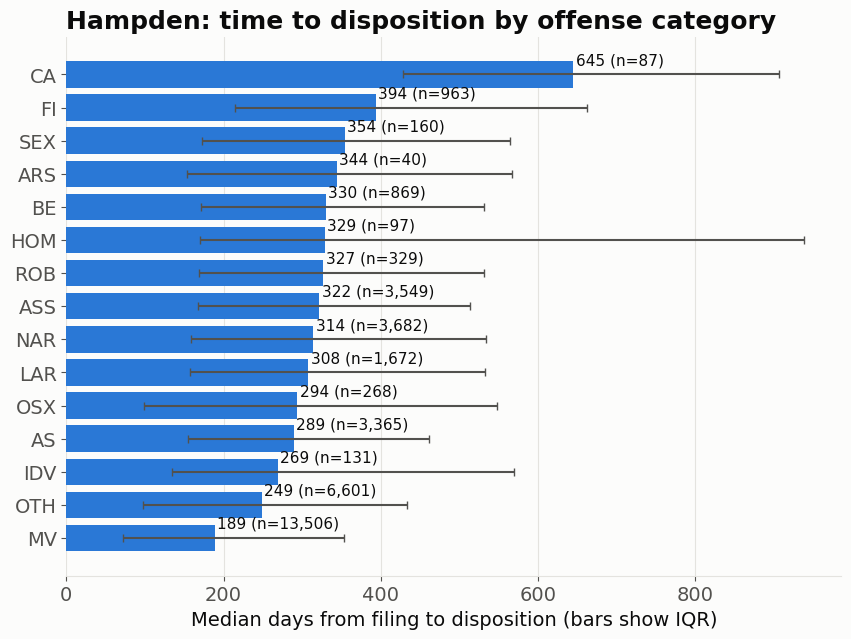

,cases,median_days,q1,q3
court,,,,
HS,841,628.0,414.0,950.0
WD,3436,252.0,122.0,427.0
SD,16812,249.0,100.0,442.0
PD,4302,244.0,101.0,450.0
Unknown,85,241.0,80.0,457.0
SJ,73,236.0,155.0,465.0
CD,4619,234.0,115.0,434.0
HD,5408,225.0,102.0,402.0


In [29]:
t = cases.copy()
t["days"] = (t["disposition_date"] - t["filing_date"]).dt.days
n_negative = (t["days"] < 0).sum()
t = t[t["days"] >= 0]
print(f"{len(t):,} cases used; {n_negative:,} negative intervals excluded")

def iqr_table(group):
    g = t.groupby(group)["days"]
    out = pd.DataFrame({"cases": g.size(), "median_days": g.median(),
                        "q1": g.quantile(0.25), "q3": g.quantile(0.75)})
    return out[out["cases"] >= MIN_CELL].sort_values("median_days", ascending=False).round(0)

by_offense = iqr_table("offense_category")
by_court = iqr_table("court")
print(f"Overall median: {t['days'].median():.0f} days (IQR {t['days'].quantile(.25):.0f}-{t['days'].quantile(.75):.0f})")

top = by_offense.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index, top["median_days"], color=OUTCOME_COLORS["Trial Conviction"])
ax.errorbar(top["median_days"], range(len(top)),
            xerr=[top["median_days"] - top["q1"], top["q3"] - top["median_days"]],
            fmt="none", ecolor=TEXT_SECONDARY, capsize=3)
for y, (m, n) in enumerate(zip(top["median_days"], top["cases"])):
    ax.text(m + 3, y + 0.3, f"{m:.0f} (n={n:,})", fontsize=11)
ax.set_xlabel("Median days from filing to disposition (bars show IQR)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"{COUNTY.title()}: time to disposition by offense category")
save_fig(fig, f"{FIG_DIR}/q6_time_by_offense.png")
plt.show()
display(by_court)

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case
- **Filters:** pending cases and negative intervals excluded; categories with fewer than 30 cases hidden

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

In [36]:
REF = {"race": "White", "sex": "Male"}  # adjust to your county's labels

def disparity(df, group, flag, label):
    g = df.groupby(group)[flag].agg(["size", "mean"]).rename(columns={"size": "cases", "mean": "rate"})
    g = g[g["cases"] >= MIN_CELL]
    ref = REF[group]
    g["rate_pct"] = (g["rate"] * 100).round(1)
    g["ratio_vs_" + ref] = (g["rate"] / g.loc[ref, "rate"]).round(2) if ref in g.index else np.nan
    return g.drop(columns="rate").assign(metric=label)

cases["dismissed"] = cases["outcome"] == "Dismissal"
results = []
for group in ["race", "sex"]:
    if group in INSUFFICIENT:
        print(f"{group}: insufficient data"); continue
    results.append(disparity(cases, group, "dismissed", "dismissal rate"))
    if "case_sent" in globals():
        inc = case_sent.join(cases.set_index("case_key")[[group]], how="inner")
        inc["incarcerated"] = inc["sentence"] == "Incarceration"
        results.append(disparity(inc, group, "incarcerated", "incarceration rate (convicted cases)"))
disp = pd.concat(results) if results else pd.DataFrame()
disp

,cases,rate_pct,ratio_vs_White,metric,ratio_vs_Male
A,461,61.4,NaN,dismissal rate,NaN
B,20588,62.6,NaN,dismissal rate,NaN
H,31209,60.2,NaN,dismissal rate,NaN
HB,73,61.6,NaN,dismissal rate,NaN
HW,918,59.9,NaN,dismissal rate,NaN
I,36,63.9,NaN,dismissal rate,NaN
U,1069,68.4,NaN,dismissal rate,NaN
Unknown,15425,70.5,NaN,dismissal rate,NaN
W,49181,53.5,NaN,dismissal rate,NaN
A,60,33.3,NaN,incarceration rate (convicted cases),NaN


,label,cases,rate_pct,ratio_vs_white
race,,,,
W,White,49181,53.5,1.0
HW,"Hispanic, White",918,59.9,1.1
H,Hispanic,31209,60.2,1.1
A,Asian,461,61.4,1.2
HB,"Hispanic, Black",73,61.6,1.2
B,Black,20588,62.6,1.2
I,I,36,63.9,1.2
U,Unknown (recorded),1069,68.4,1.3
Missing,Missing (blank),15425,70.5,1.3


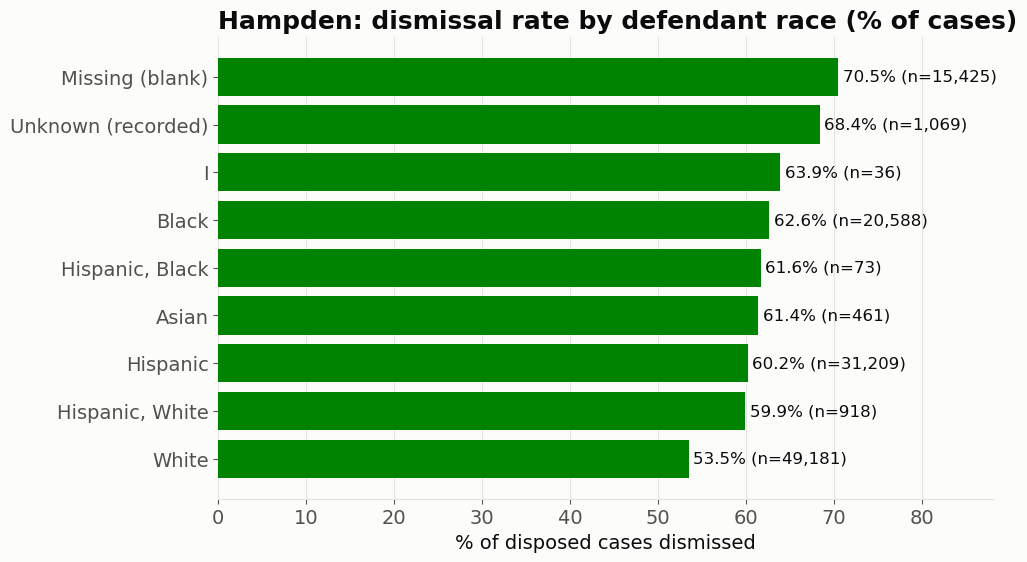

In [35]:
# Dismissal rate by race (chart): computed directly from cases so each race appears once
RACE_LABELS = {"W": "White", "B": "Black", "H": "Hispanic", "A": "Asian",
               "HW": "Hispanic, White", "HB": "Hispanic, Black",
               "U": "Unknown (recorded)", "Missing": "Missing (blank)"}   # I, other codes: confirm before labeling

if "race" not in INSUFFICIENT:
    g = cases.groupby(cases["race"].fillna("Missing").replace({"": "Missing", "Unknown": "Missing"}))["outcome"]
    r = pd.DataFrame({
        "cases": g.size(),
        "rate_pct": g.apply(lambda s: (s == "Dismissal").mean() * 100),
    })
    white_rate = r.loc["W", "rate_pct"] if "W" in r.index else np.nan
    r["ratio_vs_white"] = (r["rate_pct"] / white_rate).round(2)
    r["label"] = [RACE_LABELS.get(k, k) for k in r.index]
    r = r.sort_values("rate_pct")
    display(r[["label", "cases", "rate_pct", "ratio_vs_white"]].round(1))

    fig, ax = plt.subplots(figsize=(10, 6))
    y = np.arange(len(r))
    ax.barh(y, r["rate_pct"], color=OUTCOME_COLORS["Dismissal"])
    ax.set_yticks(y)
    ax.set_yticklabels(r["label"])
    for yi, (v, n) in enumerate(zip(r["rate_pct"], r["cases"])):
        ax.text(v + 0.5, yi, f"{v:.1f}% (n={n:,})", va="center", fontsize=12)
    ax.set_xlim(0, r["rate_pct"].max() * 1.25)
    ax.set_xlabel("% of disposed cases dismissed")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: dismissal rate by defendant race (% of cases)")
    save_fig(fig, f"{FIG_DIR}/q7_dismissal_by_race.png")
    plt.show()

**How this was calculated**
- **Unit:** disposed cases (dismissal); convicted cases (incarceration)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Filters:** groups under 30 cases suppressed; Unknown kept as its own group

**Note:** Declination (cases the prosecutor declined to file) is [measurable / not measurable] in this extract.

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

In [37]:
LOOKBACK_YEARS = 3

if "defendant_id" in missing_cols:
    print("No defendant ID: prior record not measurable, insufficient data")
elif "race" in INSUFFICIENT:
    print("Race: insufficient data")
else:
    # Use all filed cases (any year) so cases early in the window still see prior history
    hist = (filed.groupby("case_key").agg(defendant_id=("defendant_id", "first"),
                                          filing_date=("filing_date", "min"))
                 .dropna().sort_values("filing_date"))

    def prior_count(g):
        dates = g["filing_date"].values
        start = dates - np.timedelta64(365 * LOOKBACK_YEARS, "D")
        return pd.Series(np.searchsorted(dates, dates, side="left")
                         - np.searchsorted(dates, start, side="left"), index=g.index)

    hist["prior_cases"] = hist.groupby("defendant_id", group_keys=False).apply(prior_count)
    hist["prior_record"] = pd.cut(hist["prior_cases"], [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])

    c = cases.merge(hist[["prior_record"]], left_on="case_key", right_index=True, how="left")
    cell = (c.groupby(["offense_category", "prior_record", "race"], observed=True)["dismissed"]
              .agg(cases="size", rate="mean").reset_index())
    cell = cell[cell["cases"] >= MIN_CELL]
    cell["rate_pct"] = (cell["rate"] * 100).round(1)

    wide = cell.pivot_table(index=["offense_category", "prior_record"], columns="race",
                            values="rate_pct", observed=True)
    if REF["race"] in wide.columns:
        for col in wide.columns:
            if col != REF["race"]:
                wide[f"{col} ratio"] = (wide[col] / wide[REF["race"]]).round(2)
    display(wide)

/var/folders/5k/8xhyhd0j7jx98f4ydy5f5tmm0000gn/T/ipykernel_58978/2541655503.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hist["prior_cases"] = hist.groupby("defendant_id", group_keys=False).apply(prior_count)


,race,A,B,H,HW,U,Unknown,W
offense_category,prior_record,,,,,,,
AS,0,NaN,61.8,60.7,45.5,67.5,65.9,65.0
ASS,0,NaN,61.3,60.3,46.7,56.7,56.3,57.8
BE,0,NaN,42.6,39.2,NaN,NaN,27.4,36.7
CA,0,NaN,NaN,32.8,NaN,NaN,NaN,34.8
FI,0,NaN,61.1,61.3,NaN,NaN,41.5,45.7
FUG,0,NaN,93.3,91.2,NaN,NaN,100.0,90.4
HOM,0,NaN,NaN,75.8,NaN,NaN,NaN,NaN
IDV,0,NaN,63.2,44.7,NaN,NaN,NaN,55.0
LAR,0,NaN,37.6,30.2,NaN,NaN,46.4,31.7


**How this was calculated**
- **Unit:** disposed cases
- **Prior record:** earlier cases for the same defendant ID within 3 years before filing
- **Cells:** offense category × prior record × race; cells under 30 cases suppressed
- **Ratio:** group dismissal rate / White dismissal rate within the same cell

**Limitation:** Prior record only counts cases in this county's extract, not statewide history.

## Questions for the Client
- [e.g., Is a statewide prior-record field available?]
- [e.g., Can declined referrals be provided?]